# 🏅 Olympics Athlete Exploratory Data Analysis

### Exploring Olympic History, Athlete Participation, Sports, and Medal Achievements

**Dataset:** Olympic Athlete Event Dataset

## Business Objective

The Olympic Games bring together athletes from different countries to compete across various sports and events. Over the years, Olympic participation, gender representation, and sporting achievements have evolved significantly.

**Objective:**

> To analyze historical Olympic athlete data and identify meaningful patterns in athlete participation, demographics, sports representation, and medal achievements. The project aims to understand how participation has changed over time and explore the factors and trends associated with Olympic performance.

The analysis focuses on understanding athlete demographics, comparing Summer and Winter Olympics, identifying popular sports and events, and exploring medal achievements across countries and genders.


### Import necessary libraries

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import warnings 
warnings.filterwarnings("ignore")

### Visualization Theme

In [2]:
# Olympic Gold Theme
BG_COLOR = "#101C32"
GOLD = "#F5C451"
BLUE = "#3975B9"
CORAL = "#EF8175"
SKY_BLUE = "#63B3ED"
WHITE = "#FFFFFF"
GREY = "#D6DEEA"

# Set global theme
sns.set_theme(style="darkgrid")

plt.rcParams.update({
    "figure.facecolor": BG_COLOR,
    "axes.facecolor": BG_COLOR,
    "axes.edgecolor": GREY,
    "axes.labelcolor": WHITE,
    "text.color": WHITE,
    "xtick.color": GREY,
    "ytick.color": GREY,
    "grid.color": "#34435B",
    "grid.alpha": 0.5,
    "axes.titleweight": "bold",
    "axes.titlesize": 16,
    "axes.titlecolor": GOLD,
    "axes.labelsize": 11,
    "font.family": "DejaVu Sans",
    "legend.facecolor": BG_COLOR,
    "legend.edgecolor": GREY,
    "savefig.facecolor": BG_COLOR
})

### Data Loading

In [3]:
olm = pd.read_csv("athlete_data.csv")
olm

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,NaN
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,NaN
2,3,Gunnar Nielsen Aaby,M,24.0,NaN,NaN,Denmark,DEN,1920 Summer,1920,Summer,Antwerpen,Football,Football Men's Football,NaN
3,4,Edgar Lindenau Aabye,M,34.0,NaN,NaN,Denmark/Sweden,DEN,1900 Summer,1900,Summer,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold
4,5,Christine Jacoba Aaftink,F,21.0,185.0,82.0,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,Speed Skating Women's 500 metres,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
271111,135569,Andrzej ya,M,29.0,179.0,89.0,Poland-1,POL,1976 Winter,1976,Winter,Innsbruck,Luge,Luge Mixed (Men)'s Doubles,NaN
271112,135570,Piotr ya,M,27.0,176.0,59.0,Poland,POL,2014 Winter,2014,Winter,Sochi,Ski Jumping,"Ski Jumping Men's Large Hill, Individual",NaN
271113,135570,Piotr ya,M,27.0,176.0,59.0,Poland,POL,2014 Winter,2014,Winter,Sochi,Ski Jumping,"Ski Jumping Men's Large Hill, Team",NaN
271114,135571,Tomasz Ireneusz ya,M,30.0,185.0,96.0,Poland,POL,1998 Winter,1998,Winter,Nagano,Bobsleigh,Bobsleigh Men's Four,NaN


### Understand the Data

In [4]:
olm.head()

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,NaN
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,NaN
2,3,Gunnar Nielsen Aaby,M,24.0,NaN,NaN,Denmark,DEN,1920 Summer,1920,Summer,Antwerpen,Football,Football Men's Football,NaN
3,4,Edgar Lindenau Aabye,M,34.0,NaN,NaN,Denmark/Sweden,DEN,1900 Summer,1900,Summer,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold
4,5,Christine Jacoba Aaftink,F,21.0,185.0,82.0,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,Speed Skating Women's 500 metres,NaN


In [5]:
olm.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 271116 entries, 0 to 271115
Data columns (total 15 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   ID      271116 non-null  int64  
 1   Name    271116 non-null  object 
 2   Sex     271116 non-null  object 
 3   Age     261642 non-null  float64
 4   Height  210945 non-null  float64
 5   Weight  208241 non-null  float64
 6   Team    271116 non-null  object 
 7   NOC     271116 non-null  object 
 8   Games   271116 non-null  object 
 9   Year    271116 non-null  int64  
 10  Season  271116 non-null  object 
 11  City    271116 non-null  object 
 12  Sport   271116 non-null  object 
 13  Event   271116 non-null  object 
 14  Medal   39783 non-null   object 
dtypes: float64(3), int64(2), object(10)
memory usage: 31.0+ MB


In [6]:
olm.shape

(271116, 15)

In [7]:
olm.columns

Index(['ID', 'Name', 'Sex', 'Age', 'Height', 'Weight', 'Team', 'NOC', 'Games',
       'Year', 'Season', 'City', 'Sport', 'Event', 'Medal'],
      dtype='object')

In [8]:
olm.describe(include="all")

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
count,271116.000000,271116,271116,261642.000000,210945.000000,208241.000000,271116,271116,271116,271116.000000,271116,271116,271116,271116,39783
unique,NaN,134732,2,NaN,NaN,NaN,1184,230,51,NaN,2,42,66,765,3
top,NaN,Robert Tait McKenzie,M,NaN,NaN,NaN,United States,USA,2000 Summer,NaN,Summer,London,Athletics,Football Men's Football,Gold
freq,NaN,58,196594,NaN,NaN,NaN,17847,18853,13821,NaN,222552,22426,38624,5733,13372
mean,68248.954396,NaN,NaN,25.556898,175.338970,70.702393,NaN,NaN,NaN,1978.378480,NaN,NaN,NaN,NaN,NaN
std,39022.286345,NaN,NaN,6.393561,10.518462,14.348020,NaN,NaN,NaN,29.877632,NaN,NaN,NaN,NaN,NaN
min,1.000000,NaN,NaN,10.000000,127.000000,25.000000,NaN,NaN,NaN,1896.000000,NaN,NaN,NaN,NaN,NaN
25%,34643.000000,NaN,NaN,21.000000,168.000000,60.000000,NaN,NaN,NaN,1960.000000,NaN,NaN,NaN,NaN,NaN
50%,68205.000000,NaN,NaN,24.000000,175.000000,70.000000,NaN,NaN,NaN,1988.000000,NaN,NaN,NaN,NaN,NaN
75%,102097.250000,NaN,NaN,28.000000,183.000000,79.000000,NaN,NaN,NaN,2002.000000,NaN,NaN,NaN,NaN,NaN


In [9]:
olm.isnull().sum()/len(olm)*100

ID         0.000000
Name       0.000000
Sex        0.000000
Age        3.494445
Height    22.193821
Weight    23.191180
Team       0.000000
NOC        0.000000
Games      0.000000
Year       0.000000
Season     0.000000
City       0.000000
Sport      0.000000
Event      0.000000
Medal     85.326207
dtype: float64

In [10]:
olm.duplicated().sum()

np.int64(1385)

In [11]:
for col in olm.columns:
    print(f"\n{col}:")
    print(olm[col].unique())


ID:
[     1      2      3 ... 135569 135570 135571]

Name:
['A Dijiang' 'A Lamusi' 'Gunnar Nielsen Aaby' ... 'Andrzej ya' 'Piotr ya'
 'Tomasz Ireneusz ya']

Sex:
['M' 'F']

Age:
[24. 23. 34. 21. 25. 27. 31. 33. 18. 26. 22. 30. 32. 28. 54. 20. 17. 43.
 47. 29. 41. 45. 49. 53. 57. nan 19. 38. 35. 16. 37. 15. 42. 46. 40. 36.
 14. 39. 48. 52. 44. 55. 50. 71. 63. 51. 58. 13. 60. 75. 65. 56. 64. 68.
 84. 12. 72. 59. 61. 70. 74. 62. 67. 69. 73. 66. 11. 76. 88. 96. 80. 10.
 81. 77. 97.]

Height:
[180. 170.  nan 185. 188. 183. 168. 186. 182. 172. 159. 171. 184. 175.
 189. 176. 163. 187. 169. 174. 190. 194. 177. 167. 164. 198. 165. 156.
 179. 178. 166. 181. 155. 160. 173. 192. 195. 191. 203. 158. 154. 153.
 152. 193. 162. 197. 157. 207. 147. 150. 202. 161. 210. 205. 200. 148.
 208. 140. 213. 204. 151. 196. 146. 201. 132. 149. 199. 211. 215. 139.
 206. 135. 142. 217. 209. 145. 221. 144. 214. 143. 218. 127. 223. 216.
 141. 212. 131. 136. 137. 138. 220. 130. 219. 133. 128. 226.]

Weight:
[ 80.    

### Data Preprocessing

##### Handling duplicate values

In [12]:
print("Exact duplicate rows:",olm.duplicated().sum())

Exact duplicate rows: 1385


In [13]:
olm = olm.drop_duplicates()

print("Shape after removing exact duplicates:", olm.shape)

Shape after removing exact duplicates: (269731, 15)


In [14]:
olm.duplicated().sum()

np.int64(0)

##### Handling missing values

In [15]:
olm['Medal'] = olm['Medal'].fillna('No Medal')

In [16]:
olm.isnull().sum()

ID            0
Name          0
Sex           0
Age        9315
Height    58814
Weight    61527
Team          0
NOC           0
Games         0
Year          0
Season        0
City          0
Sport         0
Event         0
Medal         0
dtype: int64

In [17]:
olm

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,No Medal
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,No Medal
2,3,Gunnar Nielsen Aaby,M,24.0,NaN,NaN,Denmark,DEN,1920 Summer,1920,Summer,Antwerpen,Football,Football Men's Football,No Medal
3,4,Edgar Lindenau Aabye,M,34.0,NaN,NaN,Denmark/Sweden,DEN,1900 Summer,1900,Summer,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold
4,5,Christine Jacoba Aaftink,F,21.0,185.0,82.0,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,Speed Skating Women's 500 metres,No Medal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
271111,135569,Andrzej ya,M,29.0,179.0,89.0,Poland-1,POL,1976 Winter,1976,Winter,Innsbruck,Luge,Luge Mixed (Men)'s Doubles,No Medal
271112,135570,Piotr ya,M,27.0,176.0,59.0,Poland,POL,2014 Winter,2014,Winter,Sochi,Ski Jumping,"Ski Jumping Men's Large Hill, Individual",No Medal
271113,135570,Piotr ya,M,27.0,176.0,59.0,Poland,POL,2014 Winter,2014,Winter,Sochi,Ski Jumping,"Ski Jumping Men's Large Hill, Team",No Medal
271114,135571,Tomasz Ireneusz ya,M,30.0,185.0,96.0,Poland,POL,1998 Winter,1998,Winter,Nagano,Bobsleigh,Bobsleigh Men's Four,No Medal


In [18]:
missing = pd.DataFrame({
    'Missing Count': olm.isna().sum(),
    'Missing Percentage': (olm.isna().mean() * 100).round(2)
}).sort_values('Missing Percentage', ascending=False)
display(missing)

,Missing Count,Missing Percentage
Weight,61527,22.81
Height,58814,21.80
Age,9315,3.45
ID,0,0.00
Name,0,0.00
Sex,0,0.00
Team,0,0.00
NOC,0,0.00
Games,0,0.00
Year,0,0.00


##### Missing values were identified in Age, Height and Weight. Since these variables represent athlete-specific physical characteristics and vary across sports, genders and historical periods, missing values were retained rather than replaced with overall averages. This avoids introducing artificial values and preserves the original data distribution.*/

### Analysis 1: Age-wise Distribution

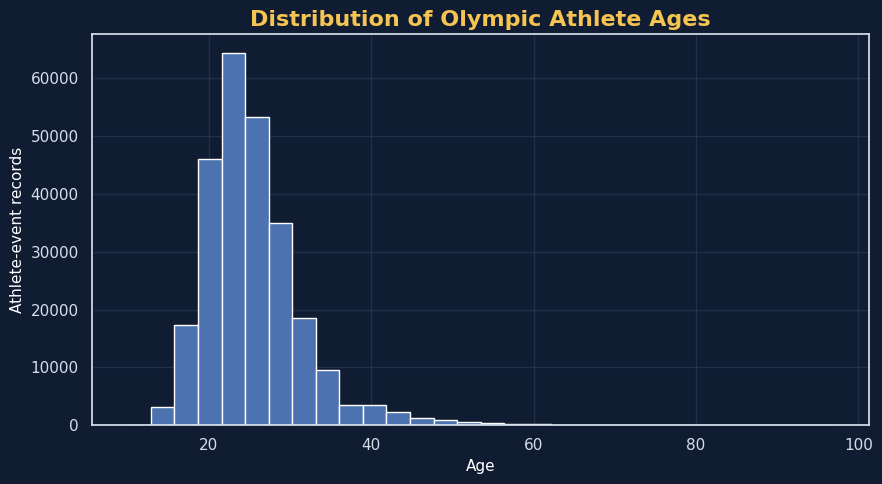

In [19]:
plt.figure(figsize=(9, 5))
plt.hist(olm['Age'].dropna(), bins=30)
plt.title('Distribution of Olympic Athlete Ages')
plt.xlabel('Age')
plt.ylabel('Athlete-event records')
plt.tight_layout()
plt.show()

`Insight:` Most Olympic athletes are concentrated in the 20–30 age group, indicating that young adults make up the largest share of Olympic participation.

### Analysis 2: Sex-wise Distribution

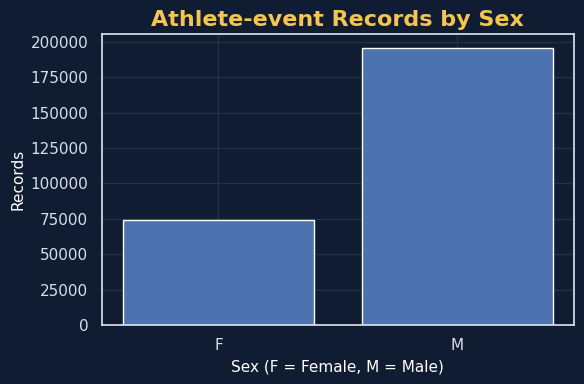

In [20]:
plt.figure(figsize=(6, 4))
sex_counts = olm['Sex'].value_counts().sort_index()
plt.bar(sex_counts.index, sex_counts.values)
plt.title('Athlete-event Records by Sex')
plt.xlabel('Sex (F = Female, M = Male)')
plt.ylabel('Records')
plt.tight_layout()
plt.show()

`Insight:` Male athletes account for a larger share of Olympic participation than female athletes, highlighting the historical gender participation gap.

### Analysis 3: Participation over Time in Summer and Winter Olympics

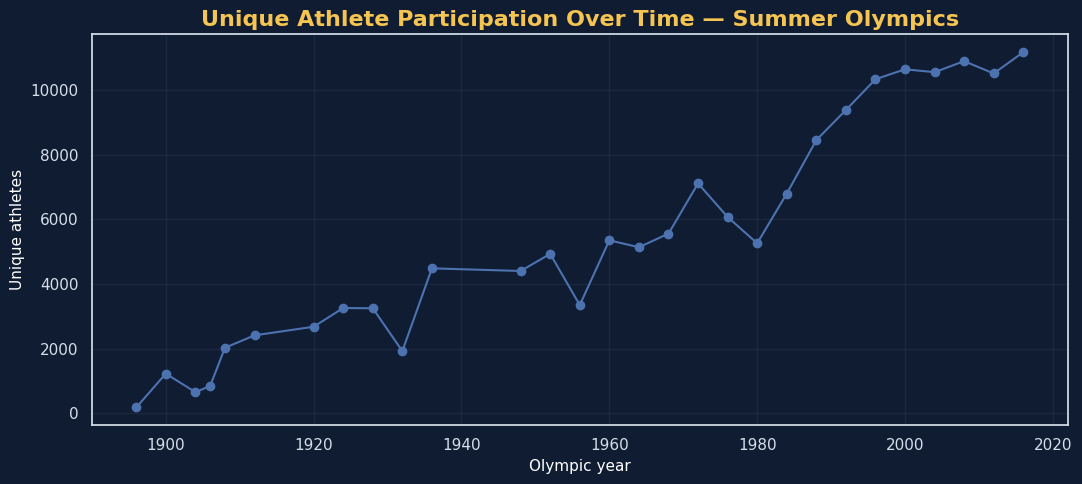

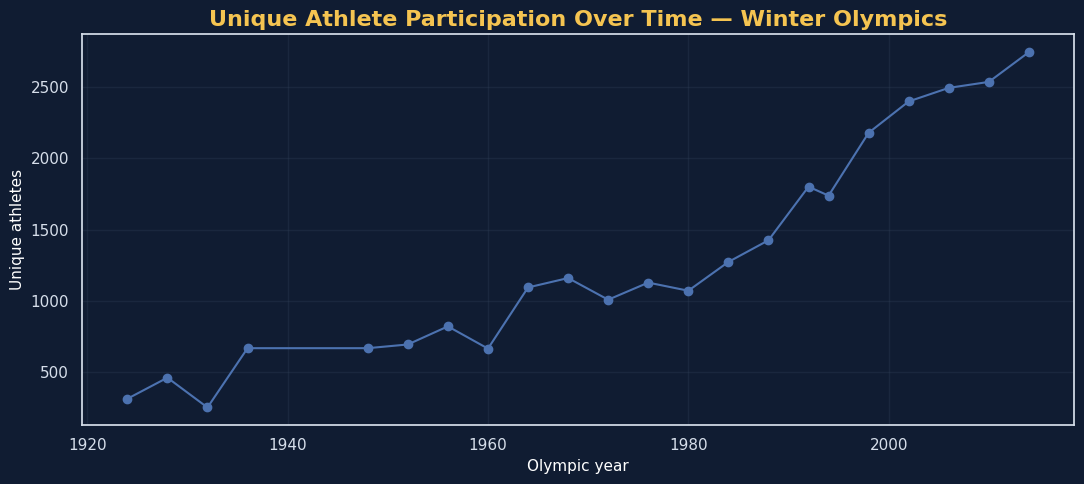

In [21]:
participation = (olm.drop_duplicates(['ID', 'Year', 'Season'])
                .groupby(['Year', 'Season'])['ID'].nunique()
                .reset_index(name='Unique Athletes'))

for season in ['Summer', 'Winter']:
    temp = participation[participation['Season'] == season].sort_values('Year')
    plt.figure(figsize=(11, 5))
    plt.plot(temp['Year'], temp['Unique Athletes'], marker='o')
    plt.title(f'Unique Athlete Participation Over Time — {season} Olympics')
    plt.xlabel('Olympic year')
    plt.ylabel('Unique athletes')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

`Insight:` Athlete participation in the Summer Olympics has increased significantly over the years, reflecting the growing scale and global reach of the competition.

In Winter Olympic participation has gradually increased across editions, showing growing international involvement in winter sports.

### Analysis 4: Top 15 Sports by Participation

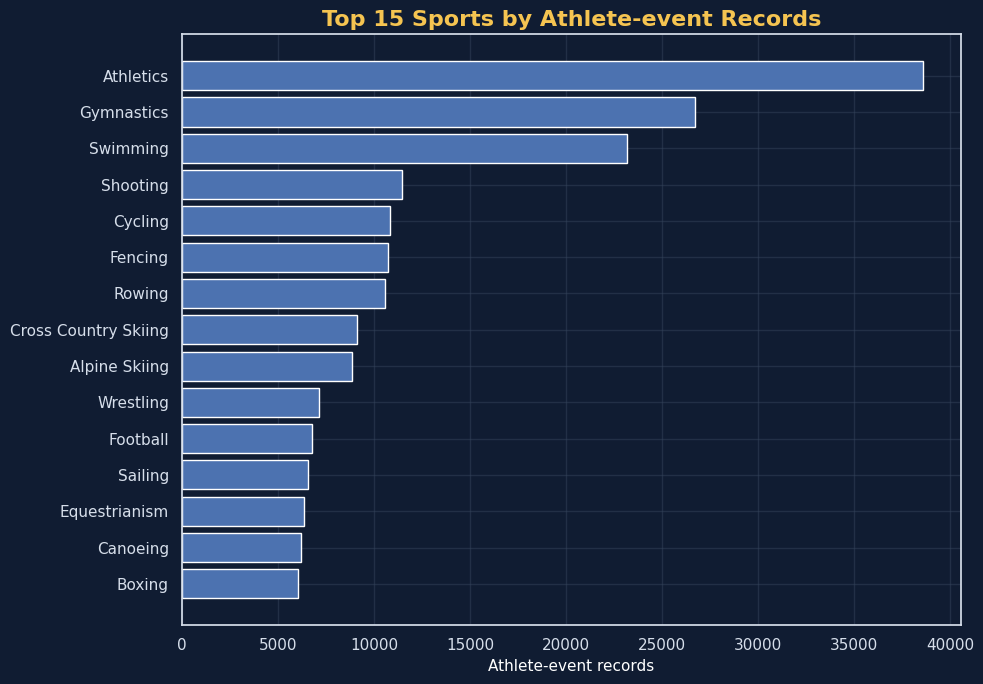

In [22]:
sport_counts = olm['Sport'].value_counts().head(15).sort_values()
plt.figure(figsize=(10, 7))
plt.barh(sport_counts.index, sport_counts.values)
plt.title('Top 15 Sports by Athlete-event Records')
plt.xlabel('Athlete-event records')
plt.tight_layout()
plt.show()

`Insight:` Athletics leads in athlete-event records, followed by Gymnastics and Swimming, highlighting their substantial representation in the Olympic Games.

### Analysis 5: Top 15 Events by Participation

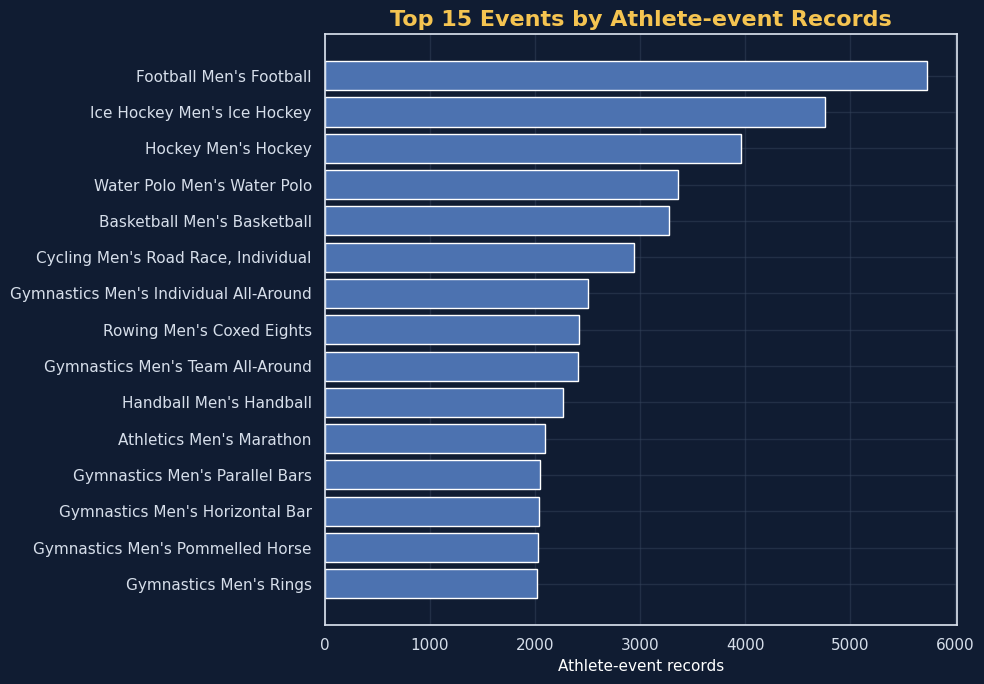

In [23]:
event_counts = olm['Event'].value_counts().head(15).sort_values()
plt.figure(figsize=(10, 7))
plt.barh(event_counts.index, event_counts.values)
plt.title('Top 15 Events by Athlete-event Records')
plt.xlabel('Athlete-event records')
plt.tight_layout()
plt.show()

`Insight:` Men's Football records the highest participation, demonstrating how team-based events contribute significantly to the total number of athlete-event records.

### Analysis 6: Top 15 NOCs by Gold Medals

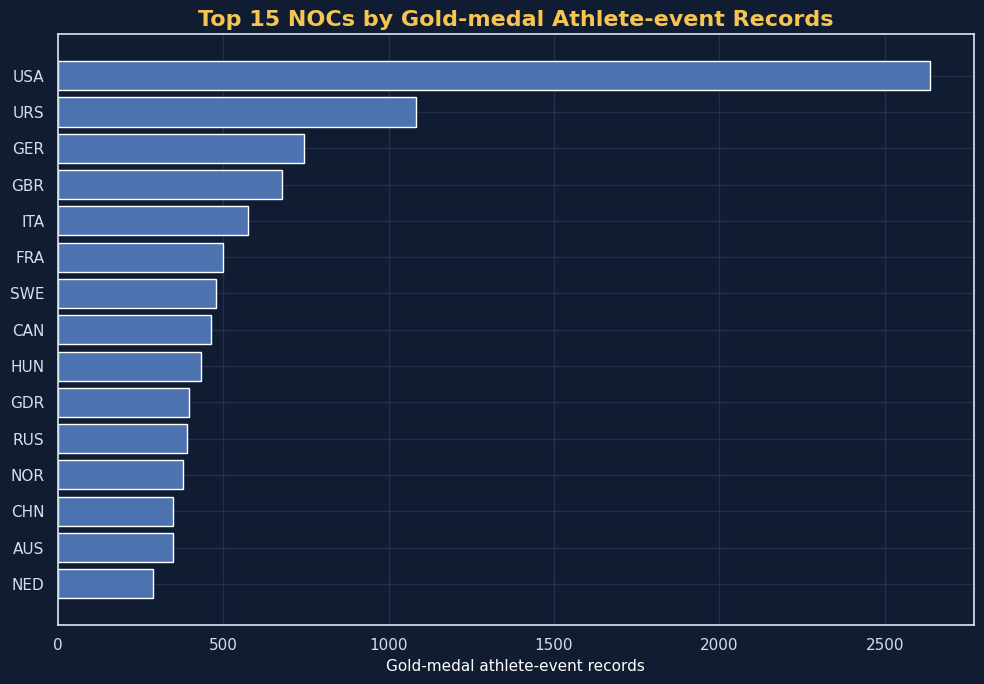

In [24]:
medal_records = olm[olm['Medal'].notna()]
top_gold = medal_records[medal_records['Medal'] == 'Gold']['NOC'].value_counts().head(15).sort_values()
plt.figure(figsize=(10, 7))
plt.barh(top_gold.index, top_gold.values)
plt.title('Top 15 NOCs by Gold-medal Athlete-event Records')
plt.xlabel('Gold-medal athlete-event records')
plt.tight_layout()
plt.show()

`Insight:` The United States leads in gold-medal athlete-event records, followed by the Soviet Union and Germany, reflecting their strong historical Olympic performances.

### Analysis 7: Medal Distribution

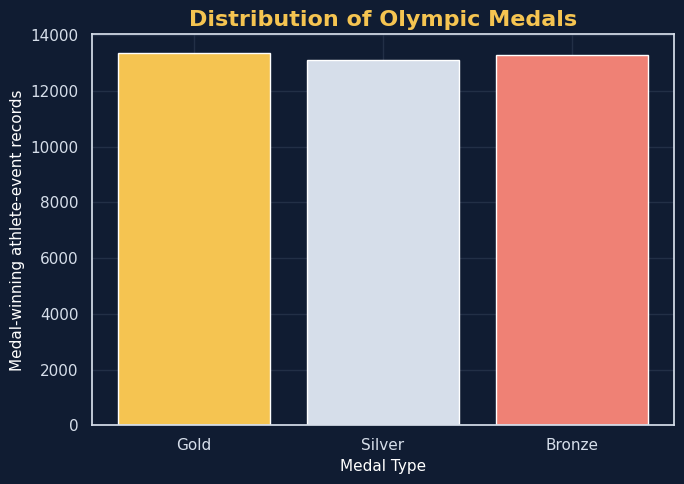

In [25]:
medal_counts = (
    olm[olm['Medal'] != 'No Medal']['Medal']
    .value_counts()
    .reindex(['Gold', 'Silver', 'Bronze']))

plt.figure(figsize=(7, 5))
plt.bar(
    medal_counts.index,
    medal_counts.values,
    color=[GOLD, GREY, CORAL])

plt.title('Distribution of Olympic Medals')
plt.xlabel('Medal Type')
plt.ylabel('Medal-winning athlete-event records')

plt.tight_layout()
plt.show()

`Insight:` Most athlete-event records do not result in a medal, while the remaining records are distributed across Gold, Silver and Bronze awards.

### Analysis 8: Top 10 Countries by Total Medals

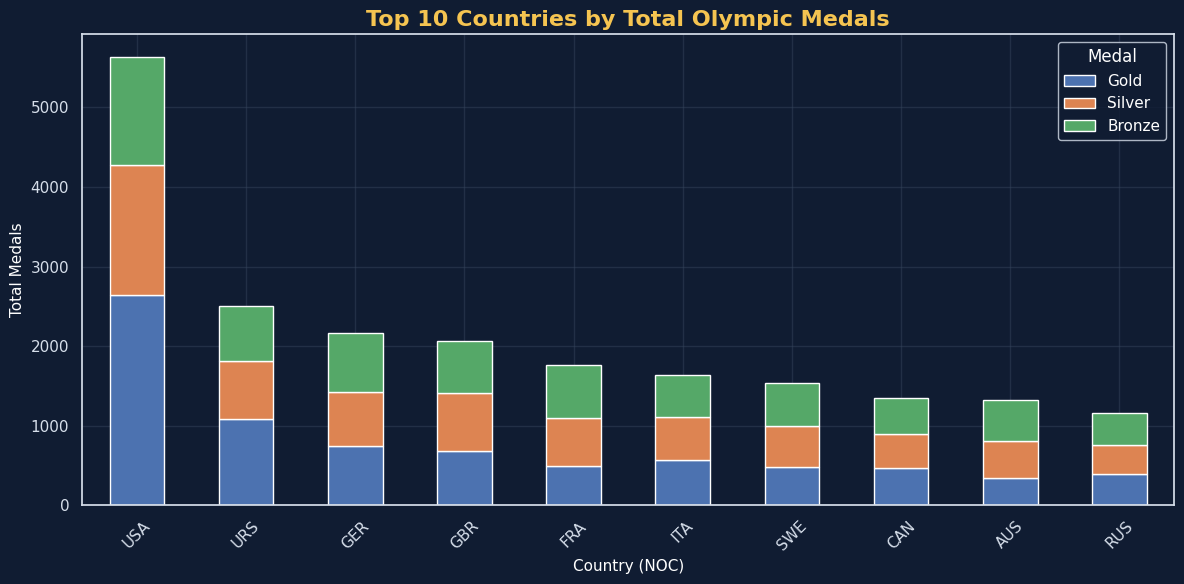

In [26]:
medal_data = olm[olm['Medal'] != 'No Medal']

country_medals = (
    medal_data.groupby(["NOC", "Medal"])
    .size()
    .unstack(fill_value=0)
)

country_medals["Total"] = country_medals[
    ["Gold", "Silver", "Bronze"]
].sum(axis=1)

top_countries = country_medals.nlargest(10, "Total")

top_countries[["Gold", "Silver", "Bronze"]].plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("Top 10 Countries by Total Olympic Medals")
plt.xlabel("Country (NOC)")
plt.ylabel("Total Medals")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

`Insight:` This chart compares the overall Olympic medal performance of the top 10 countries across Gold, Silver and Bronze medals.

### Analysis 9: Host Country Participation

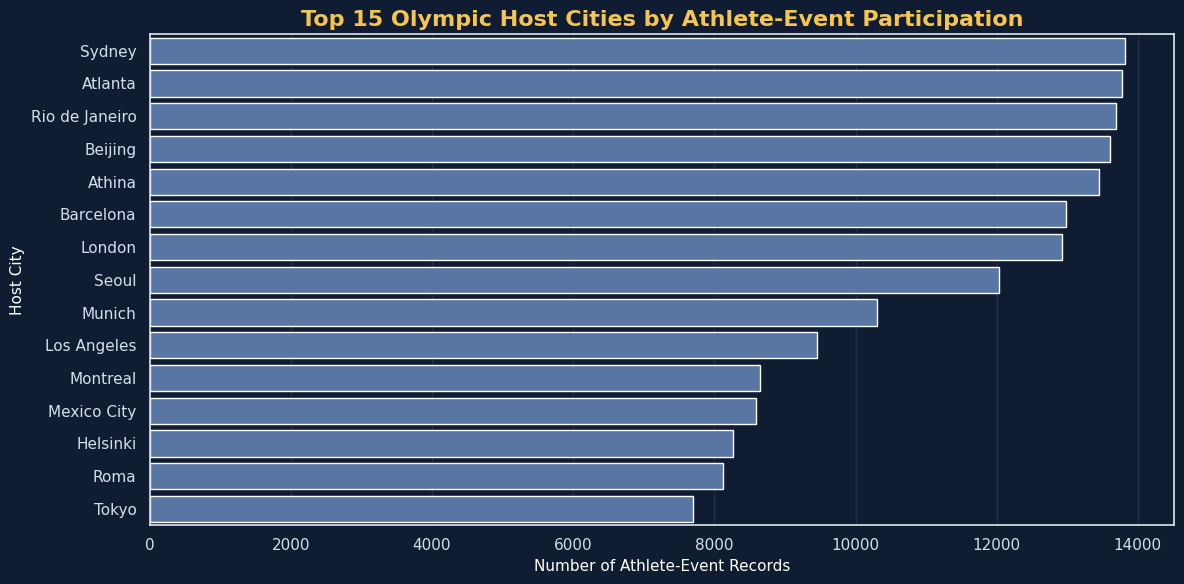

In [27]:
host_data = (
    olm.groupby(["Year", "City"])["ID"]
    .count()
    .reset_index(name="Participation")
)

host_data = host_data.sort_values("Participation", ascending=False).head(15)

plt.figure(figsize=(12, 6))
sns.barplot(
    data=host_data,
    x="Participation",
    y="City"
)

plt.title("Top 15 Olympic Host Cities by Athlete-Event Participation")
plt.xlabel("Number of Athlete-Event Records")
plt.ylabel("Host City")
plt.tight_layout()
plt.show()

`Insight:` This chart compares participation levels across Olympic host cities and highlights editions with the largest athlete-event records.

### Analysis 10: Medal Records by Gender

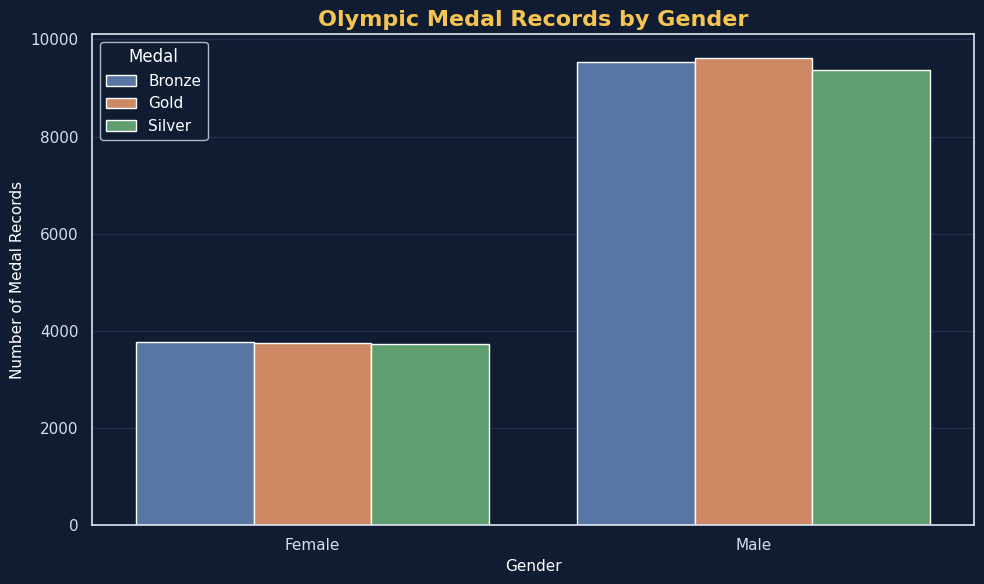

In [28]:
gender_medals = (
    olm[olm['Medal'] != 'No Medal']
    .groupby(['Sex', 'Medal'])
    .size()
    .reset_index(name='Count')
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=gender_medals,
    x='Sex',
    y='Count',
    hue='Medal'
)

plt.title('Olympic Medal Records by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Medal Records')
plt.xticks([0, 1], ['Female', 'Male'])

plt.tight_layout()
plt.show()

`Insight:` Male athletes have more medal records across all categories, while female athletes show growing representation in Olympic medal achievements.

### Analysis 11: Medal Achievements by Age Group

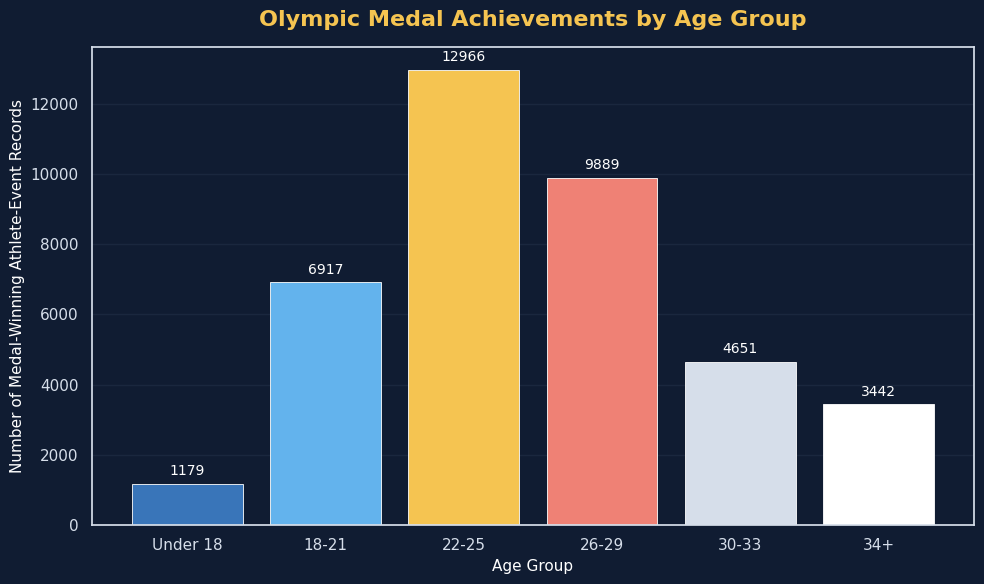

In [29]:
# Exclude records without medals
medal_age = olm[olm['Medal'] != 'No Medal'].copy()

# Create age groups
bins = [0, 17, 21, 25, 29, 33, 100]
labels = ['Under 18', '18-21', '22-25', '26-29', '30-33', '34+']

medal_age['Age Group'] = pd.cut(
    medal_age['Age'],
    bins=bins,
    labels=labels,
    include_lowest=True
)

# Count medal-winning athlete-event records
age_medals = (
    medal_age.groupby('Age Group', observed=False)
    .size()
    .reindex(labels, fill_value=0)
)

# Visualization
plt.figure(figsize=(10, 6))

bars = plt.bar(
    age_medals.index.astype(str),
    age_medals.values,
    color=[BLUE, SKY_BLUE, GOLD, CORAL, GREY, WHITE],
    edgecolor=WHITE,
    linewidth=0.6
)

plt.title('Olympic Medal Achievements by Age Group', pad=15)
plt.xlabel('Age Group')
plt.ylabel('Number of Medal-Winning Athlete-Event Records')

plt.bar_label(bars, padding=4, color=WHITE, fontsize=10)

plt.grid(axis='y', alpha=0.3)
plt.grid(axis='x', visible=False)

plt.tight_layout()
plt.show()

`Insight:` Medal achievements vary by age group, highlighting the role of age and experience in Olympic success.

### Analysis 12: Female vs Male Participation Over Time

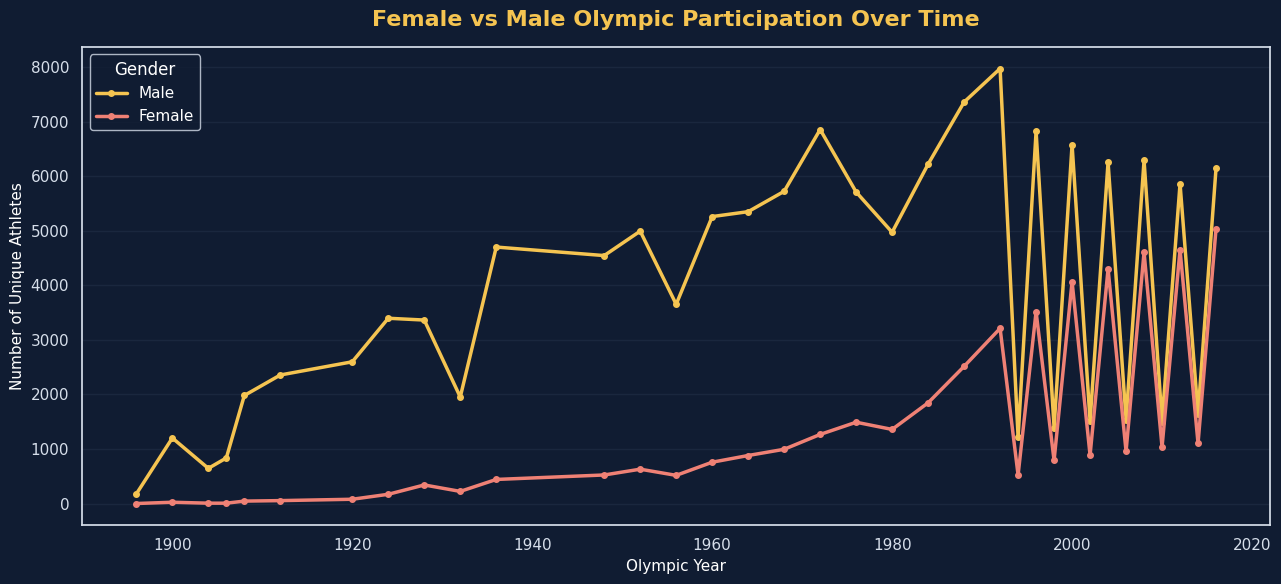

In [30]:
# Remove repeated event records for the same athlete
participation_gender = (
    olm.drop_duplicates(subset=['ID', 'Year', 'Sex'])
    .groupby(['Year', 'Sex'])['ID']
    .nunique()
    .reset_index(name='Unique Athletes')
)

# Pivot data for plotting
gender_trend = participation_gender.pivot(
    index='Year',
    columns='Sex',
    values='Unique Athletes'
).fillna(0)

# Visualization
plt.figure(figsize=(13, 6))

plt.plot(
    gender_trend.index,
    gender_trend['M'],
    color=GOLD,
    marker='o',
    markersize=4,
    linewidth=2.5,
    label='Male'
)

plt.plot(
    gender_trend.index,
    gender_trend['F'],
    color=CORAL,
    marker='o',
    markersize=4,
    linewidth=2.5,
    label='Female'
)

plt.title('Female vs Male Olympic Participation Over Time', pad=15)
plt.xlabel('Olympic Year')
plt.ylabel('Number of Unique Athletes')

plt.legend(title='Gender', loc='upper left')
plt.grid(axis='y', alpha=0.3)
plt.grid(axis='x', visible=False)

plt.tight_layout()
plt.show()

`Insight:` Female participation has increased over Olympic editions, narrowing the gender participation gap.

### Analysis 13: Top Countries by Sport

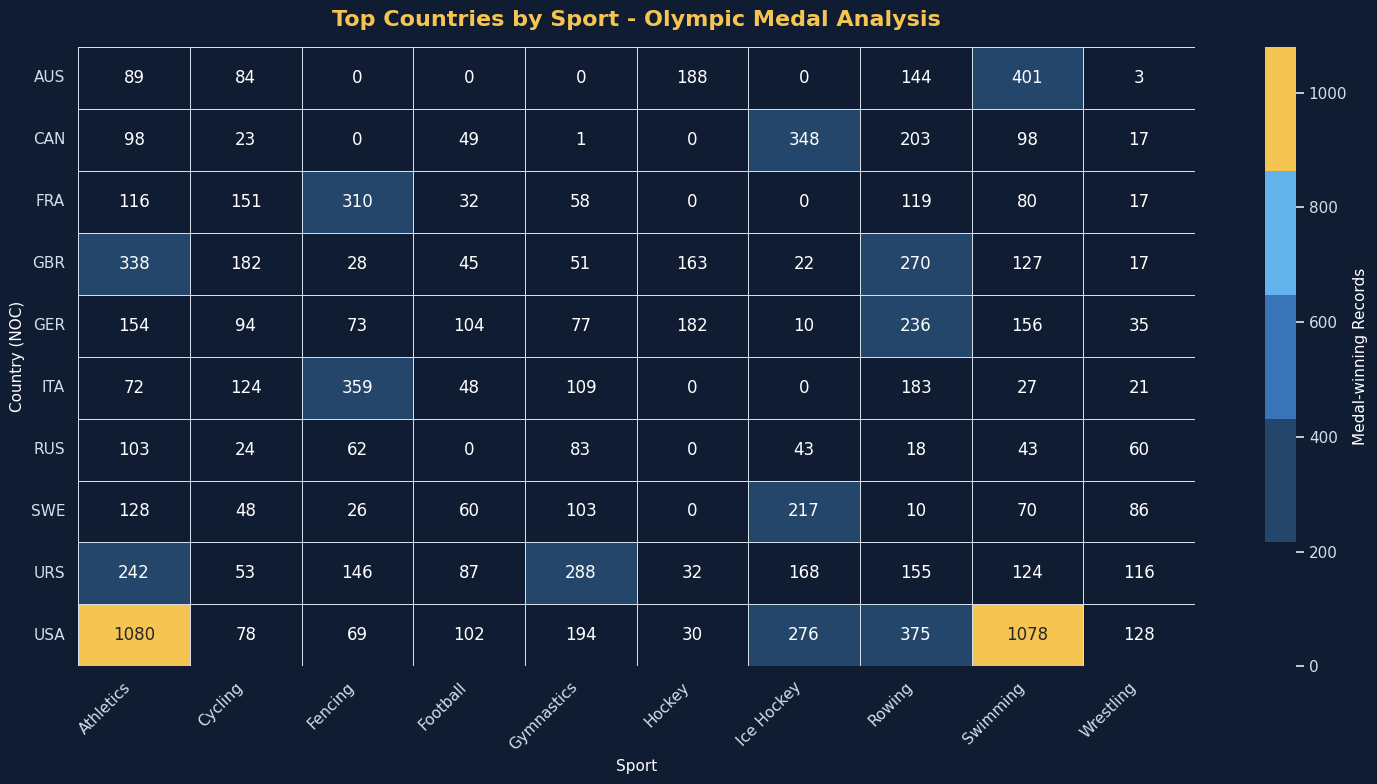

In [31]:
# Consider only medal-winning records
sport_medals = olm[
    olm['Medal'] != 'No Medal'
].copy()

# Find top 10 countries by total medal records
top_nocs = (
    sport_medals['NOC']
    .value_counts()
    .head(10)
    .index
)

# Find top 10 sports by total medal records
top_sports = (
    sport_medals['Sport']
    .value_counts()
    .head(10)
    .index
)

# Filter top countries and sports
heatmap_data = sport_medals[
    (sport_medals['NOC'].isin(top_nocs)) &
    (sport_medals['Sport'].isin(top_sports))
]

# Create country vs sport table
country_sport = pd.crosstab(
    heatmap_data['NOC'],
    heatmap_data['Sport']
)

# Visualization
plt.figure(figsize=(15, 8))

sns.heatmap(
    country_sport,
    annot=True,
    fmt='d',
    cmap=sns.color_palette(
        ['#101C32', '#24466B', '#3975B9', '#63B3ED', '#F5C451'],
        as_cmap=True
    ),
    linewidths=0.5,
    linecolor=GREY,
    cbar_kws={'label': 'Medal-winning Records'}
)

plt.title('Top Countries by Sport - Olympic Medal Analysis', pad=15)
plt.xlabel('Sport')
plt.ylabel('Country (NOC)')

plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

`Insight:` Countries show different sporting strengths, with varying medal performances across different sports.

## 📊 Key Insights

1. **Age Distribution:** Most Olympic athlete-event records belong to athletes between 20 and 30 years of age, highlighting the strong representation of young adults in Olympic competitions.

2. **Gender Representation:** Male athletes account for a larger share of Olympic participation than female athletes, reflecting the historical gender participation gap.

3. **Olympic Participation Trends:** Summer Olympics have significantly higher athlete participation than Winter Olympics, demonstrating their larger scale of participation.

4. **Popular Sports:** Athletics, Gymnastics, and Swimming are among the most represented sports, highlighting their significant contribution to Olympic participation.

5. **Popular Events:** Men's Football records the highest participation among the analyzed events, showing the substantial representation of team-based competitions.

6. **Country Performance:** The United States leads in gold-medal athlete-event records among the leading National Olympic Committees, reflecting its strong historical Olympic performance.

7. **Medal Distribution:** Most athlete-event records do not result in a medal, while the remaining records are distributed across Gold, Silver, and Bronze awards.

8. **Female Participation:** Female athlete participation has increased across Olympic editions, highlighting the growing representation of women in the Games.

9. **Medal Records by Gender:** Male athletes have more medal records across all three categories, while female athletes also demonstrate significant representation in Olympic medal achievements.

10. **Overall Observation:** Olympic participation and achievements vary across age groups, genders, sports, countries, and Olympic editions. Exploring these dimensions together provides a broader understanding of Olympic history.

11. **Age-wise Achievements:** Medal achievements vary across different age groups.

12. **Gender Trends:** Female participation has increased across Olympic editions.

13. **Country Performance:** Countries demonstrate different strengths across sporting disciplines.

## ✅ Conclusion

The Exploratory Data Analysis of the Olympic Athlete Dataset provides valuable insights into historical Olympic participation, athlete demographics, sports representation, and medal achievements.

The analysis explores important aspects such as age distribution, gender participation, popular sports, Olympic trends, country performance, and medal distribution. It highlights how Olympic participation and representation have evolved across different editions of the Games.

The findings help identify patterns in athlete participation and understand the historical performance of countries across various sporting events.

Overall, this project demonstrates how Python libraries such as Pandas, Matplotlib, and Seaborn can transform raw Olympic data into meaningful insights through data analysis and visualization.